# Smart Energy Consumption Forecasting Using Machine Learning

Forecasting household electricity consumption (next hour and next day) from historical usage.

**Dataset:** [Individual Household Electric Power Consumption (UCI)](https://archive.ics.uci.edu/dataset/235/individual+household+electric+power+consumption) - one household, one-minute readings, Dec 2006 - Nov 2010.

**Target:** `Global_active_power` (kW), aggregated to hourly values.

**Pipeline:** data collection -> cleaning -> EDA -> feature engineering -> model training and comparison -> forecasting -> insights.

## 1. Data Collection

In [3]:
# ---------- Download the dataset from UCI ----------
import urllib.request, zipfile, os

url = "http://archive.ics.uci.edu/static/public/235/individual+household+electric+power+consumption.zip"

print("Downloading dataset...")
urllib.request.urlretrieve(url, "data.zip")
print("Download complete. Extracting...")

with zipfile.ZipFile("data.zip") as z:
    z.extractall(".")

print(os.listdir("."))

Download complete. Extracting...
['.config', 'household_power_consumption.txt', 'data.zip', 'individual+household+electric+power+consumption.zip', 'sample_data']


In [4]:
# ---------- Data Collection ----------
import pandas as pd
import numpy as np

# Load the dataset (missing values are marked with "?" in this file)
df = pd.read_csv(
    "household_power_consumption.txt",
    sep=";",
    low_memory=False,
    na_values=["?"]
)

# Basic inspection
print("Shape:", df.shape)
print(df.head())

Shape: (2075259, 9)
         Date      Time  Global_active_power  Global_reactive_power  Voltage  \
0  16/12/2006  17:24:00                4.216                  0.418   234.84   
1  16/12/2006  17:25:00                5.360                  0.436   233.63   
2  16/12/2006  17:26:00                5.374                  0.498   233.29   
3  16/12/2006  17:27:00                5.388                  0.502   233.74   
4  16/12/2006  17:28:00                3.666                  0.528   235.68   

   Global_intensity  Sub_metering_1  Sub_metering_2  Sub_metering_3  
0              18.4             0.0             1.0            17.0  
1              23.0             0.0             1.0            16.0  
2              23.0             0.0             2.0            17.0  
3              23.0             0.0             1.0            17.0  
4              15.8             0.0             1.0            17.0  


## 2. Data Understanding

In [5]:
# ---------- Data Understanding ----------

# Dataset information (columns, data types, memory usage)
print("=== Dataset Information ===")
df.info()

# Missing values in each column
print("\n=== Missing Values ===")
print(df.isnull().sum())

# Duplicate rows
print("\n=== Duplicate Records ===")
print("Total duplicate rows:", df.duplicated().sum())

# Date range of the dataset
print("\n=== Date Range ===")
print("Start date:", df["Date"].iloc[0])
print("End date:", df["Date"].iloc[-1])

# Statistical summary of numerical columns
print("\n=== Statistical Summary ===")
print(df.describe())

=== Dataset Information ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2075259 entries, 0 to 2075258
Data columns (total 9 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Date                   object 
 1   Time                   object 
 2   Global_active_power    float64
 3   Global_reactive_power  float64
 4   Voltage                float64
 5   Global_intensity       float64
 6   Sub_metering_1         float64
 7   Sub_metering_2         float64
 8   Sub_metering_3         float64
dtypes: float64(7), object(2)
memory usage: 142.5+ MB

=== Missing Values ===
Date                         0
Time                         0
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
dtype: int64

=== Duplicate Records ===
Total duplicate rows: 0

=== Date Range ===
Start date: 16/12/2006


## 3. Data Cleaning and Preprocessing

In [6]:
# ---------- Data Cleaning ----------

# 1. Combine Date and Time into a single datetime column
df["Datetime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    format="%d/%m/%Y %H:%M:%S"
)

# 2. Drop the old Date and Time columns (no longer needed)
df = df.drop(columns=["Date", "Time"])

# 3. Sort in chronological order and use Datetime as the index
df = df.sort_values("Datetime").set_index("Datetime")

# 4. Remove duplicate timestamps (if any)
df = df[~df.index.duplicated(keep="first")]

# 5. Fill short gaps (up to 60 minutes) using time-based interpolation
df = df.interpolate(method="time", limit=60)

# Check the result
print("Shape:", df.shape)
print("Start:", df.index.min())
print("End:", df.index.max())
print("\nMissing values after cleaning:")
print(df.isnull().sum())
print(df.head())

Shape: (2075259, 7)
Start: 2006-12-16 17:24:00
End: 2010-11-26 21:02:00

Missing values after cleaning:
Global_active_power      25151
Global_reactive_power    25151
Voltage                  25151
Global_intensity         25151
Sub_metering_1           25151
Sub_metering_2           25151
Sub_metering_3           25151
dtype: int64
                     Global_active_power  Global_reactive_power  Voltage  \
Datetime                                                                   
2006-12-16 17:24:00                4.216                  0.418   234.84   
2006-12-16 17:25:00                5.360                  0.436   233.63   
2006-12-16 17:26:00                5.374                  0.498   233.29   
2006-12-16 17:27:00                5.388                  0.502   233.74   
2006-12-16 17:28:00                3.666                  0.528   235.68   

                     Global_intensity  Sub_metering_1  Sub_metering_2  \
Datetime                                                    

In [7]:
# ---------- Convert minute data to hourly data ----------

# Power, voltage, intensity: average per hour
# Sub-metering (energy in Wh): total per hour
# min_count=1 keeps an hour as missing if ALL its minutes are missing
hourly = df.resample("h").agg({
    "Global_active_power": "mean",
    "Global_reactive_power": "mean",
    "Voltage": "mean",
    "Global_intensity": "mean",
    "Sub_metering_1": lambda x: x.sum(min_count=1),
    "Sub_metering_2": lambda x: x.sum(min_count=1),
    "Sub_metering_3": lambda x: x.sum(min_count=1),
})

# Fill only very short gaps (up to 3 hours) by interpolation
hourly = hourly.interpolate(method="time", limit=3)

print("Hourly shape:", hourly.shape)
print("\nMissing values (hourly):")
print(hourly.isnull().sum())
print("\nMissing hours: {:.2f}% of all hours".format(
    hourly["Global_active_power"].isnull().mean() * 100))
print(hourly.head())

Hourly shape: (34589, 7)

Missing values (hourly):
Global_active_power      392
Global_reactive_power    392
Voltage                  392
Global_intensity         392
Sub_metering_1           392
Sub_metering_2           392
Sub_metering_3           392
dtype: int64

Missing hours: 1.13% of all hours
                     Global_active_power  Global_reactive_power     Voltage  \
Datetime                                                                      
2006-12-16 17:00:00             4.222889               0.229000  234.643889   
2006-12-16 18:00:00             3.632200               0.080033  234.580167   
2006-12-16 19:00:00             3.400233               0.085233  233.232500   
2006-12-16 20:00:00             3.268567               0.075100  234.071500   
2006-12-16 21:00:00             3.056467               0.076667  237.158667   

                     Global_intensity  Sub_metering_1  Sub_metering_2  \
Datetime                                                               

## 4. Outlier Detection

Q1: 0.342 | Q3: 1.579
Lower limit: -1.514 | Upper limit: 3.435
Number of outliers: 733
Percentage of outliers: 2.14%
Maximum value: 6.561


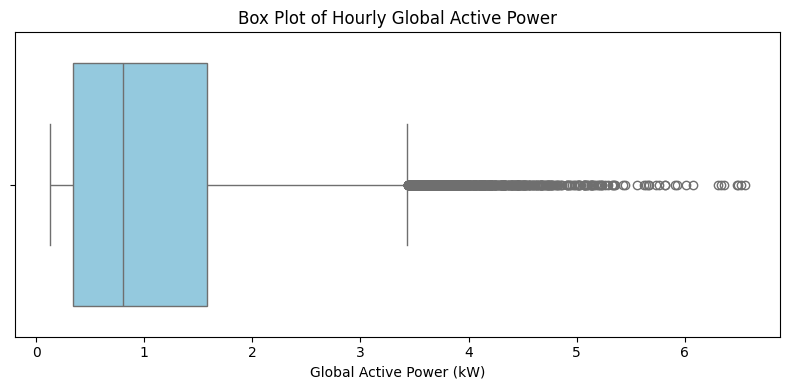

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Save the hourly data so we do not repeat cleaning later
hourly.to_csv("hourly_clean.csv")

# ---------- Outlier detection using the IQR method ----------
col = hourly["Global_active_power"].dropna()

Q1 = col.quantile(0.25)
Q3 = col.quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = col[(col < lower) | (col > upper)]

print("Q1:", round(Q1, 3), "| Q3:", round(Q3, 3))
print("Lower limit:", round(lower, 3), "| Upper limit:", round(upper, 3))
print("Number of outliers:", len(outliers))
print("Percentage of outliers: {:.2f}%".format(len(outliers) / len(col) * 100))
print("Maximum value:", round(col.max(), 3))

# ---------- Box plot ----------
plt.figure(figsize=(8, 4))
sns.boxplot(x=col, color="skyblue")
plt.title("Box Plot of Hourly Global Active Power")
plt.xlabel("Global Active Power (kW)")
plt.tight_layout()
plt.savefig("boxplot_outliers.png", dpi=150)
plt.show()

## 5. Exploratory Data Analysis (EDA)

Average consumption: 1.091 kW
Maximum consumption: 6.561 kW at 2008-11-23 18:00:00
Minimum consumption: 0.124 kW at 2008-08-23 21:00:00


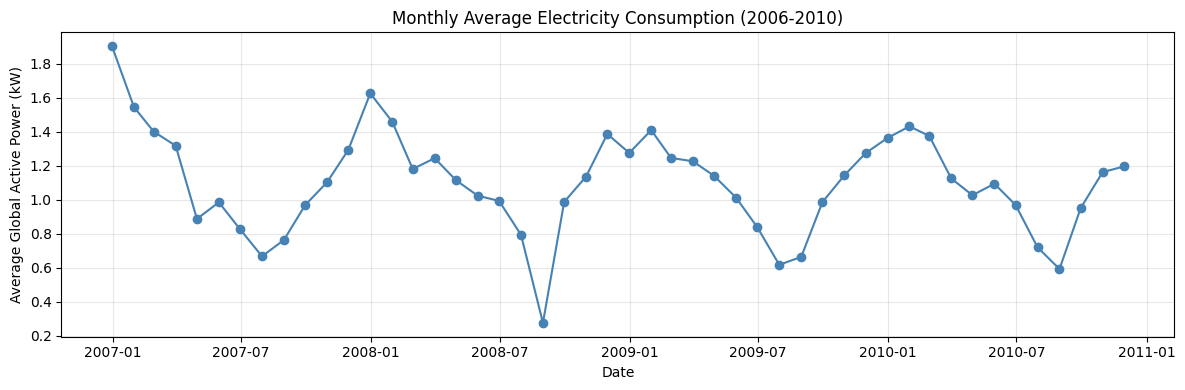

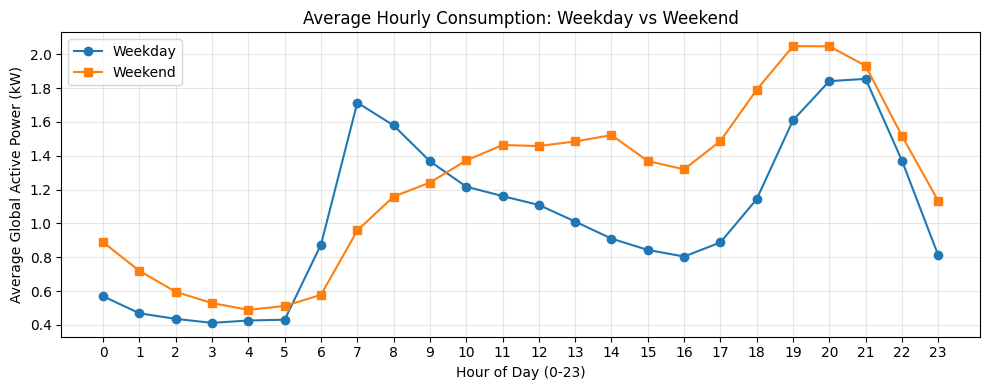

Peak consumption hour (average): 20 :00


In [9]:
# ---------- Exploratory Data Analysis (EDA) ----------

# Work on a copy and create time-based columns
eda = hourly.copy()
eda["Hour"] = eda.index.hour
eda["DayOfWeek"] = eda.index.dayofweek          # 0 = Monday, 6 = Sunday
eda["Month"] = eda.index.month
eda["Is_Weekend"] = (eda["DayOfWeek"] >= 5).astype(int)

target = "Global_active_power"

# 1. Basic statistics
print("Average consumption: {:.3f} kW".format(eda[target].mean()))
print("Maximum consumption: {:.3f} kW at {}".format(eda[target].max(), eda[target].idxmax()))
print("Minimum consumption: {:.3f} kW at {}".format(eda[target].min(), eda[target].idxmin()))

# 2. Line chart: monthly average consumption over time
monthly = eda[target].resample("ME").mean()
plt.figure(figsize=(12, 4))
plt.plot(monthly.index, monthly.values, marker="o", color="steelblue")
plt.title("Monthly Average Electricity Consumption (2006-2010)")
plt.xlabel("Date")
plt.ylabel("Average Global Active Power (kW)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("monthly_trend.png", dpi=150)
plt.show()

# 3. Daily pattern: average consumption by hour (weekday vs weekend)
hourly_pattern = eda.groupby(["Hour", "Is_Weekend"])[target].mean().unstack()
hourly_pattern.columns = ["Weekday", "Weekend"]

plt.figure(figsize=(10, 4))
plt.plot(hourly_pattern.index, hourly_pattern["Weekday"], marker="o", label="Weekday")
plt.plot(hourly_pattern.index, hourly_pattern["Weekend"], marker="s", label="Weekend")
plt.title("Average Hourly Consumption: Weekday vs Weekend")
plt.xlabel("Hour of Day (0-23)")
plt.ylabel("Average Global Active Power (kW)")
plt.xticks(range(0, 24))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("hourly_weekday_weekend.png", dpi=150)
plt.show()

# Peak hour
peak_hour = eda.groupby("Hour")[target].mean().idxmax()
print("Peak consumption hour (average):", peak_hour, ":00")

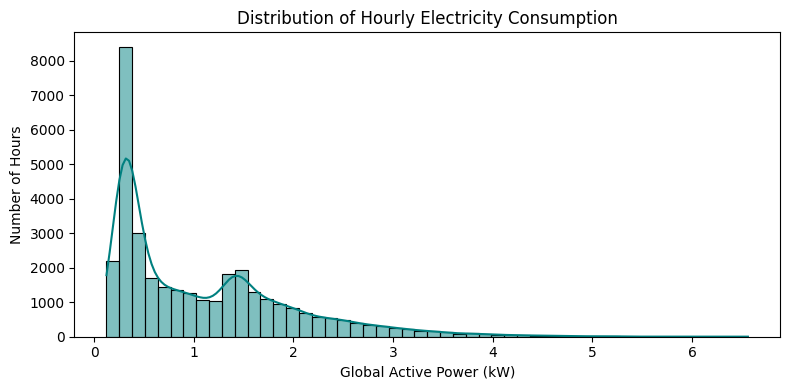

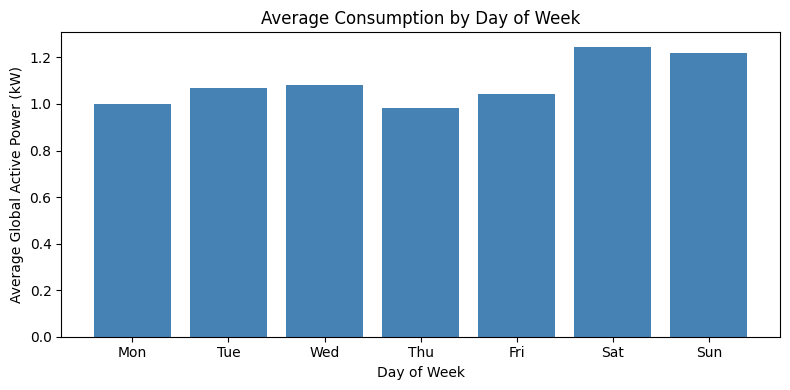

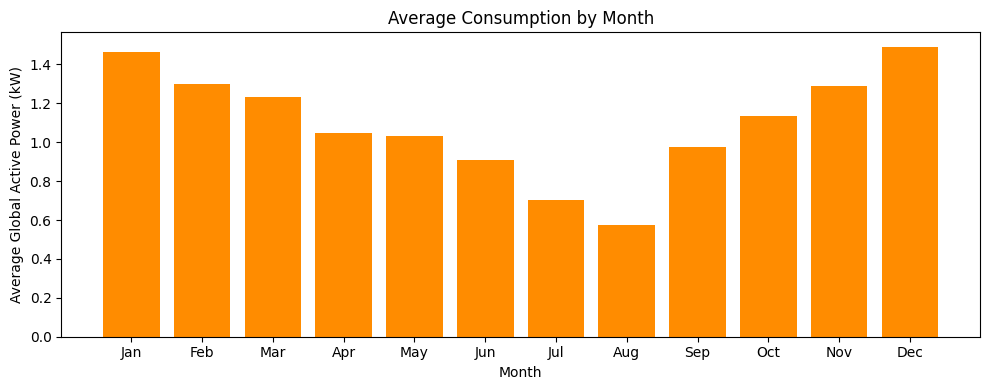

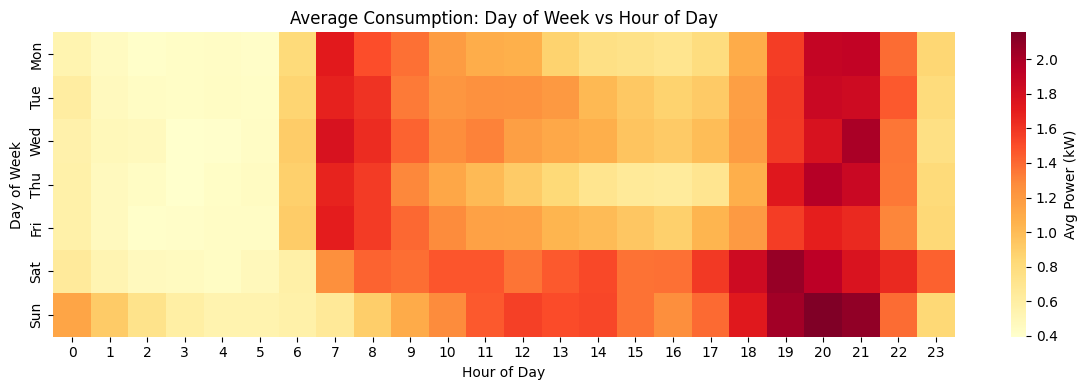

Highest-usage day of week: Sat
Lowest-usage day of week: Thu
Highest-usage month: Dec
Lowest-usage month: Aug
Weekday average: 1.036 kW
Weekend average: 1.233 kW


In [10]:
# ---------- EDA (continued) ----------
target = "Global_active_power"
day_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
               "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

# 1. Histogram: distribution of consumption
plt.figure(figsize=(8, 4))
sns.histplot(eda[target].dropna(), bins=50, kde=True, color="teal")
plt.title("Distribution of Hourly Electricity Consumption")
plt.xlabel("Global Active Power (kW)")
plt.ylabel("Number of Hours")
plt.tight_layout()
plt.savefig("histogram_distribution.png", dpi=150)
plt.show()

# 2. Bar chart: average consumption by day of week
dow = eda.groupby("DayOfWeek")[target].mean()
plt.figure(figsize=(8, 4))
plt.bar(day_names, dow.values, color="steelblue")
plt.title("Average Consumption by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Global Active Power (kW)")
plt.tight_layout()
plt.savefig("barchart_day_of_week.png", dpi=150)
plt.show()

# 3. Bar chart: average consumption by month of year
mon = eda.groupby("Month")[target].mean()
plt.figure(figsize=(10, 4))
plt.bar(month_names, mon.values, color="darkorange")
plt.title("Average Consumption by Month")
plt.xlabel("Month")
plt.ylabel("Average Global Active Power (kW)")
plt.tight_layout()
plt.savefig("barchart_monthly_average.png", dpi=150)
plt.show()

# 4. Heatmap: hour of day vs day of week
pivot = eda.pivot_table(values=target, index="DayOfWeek",
                        columns="Hour", aggfunc="mean")
pivot.index = day_names
plt.figure(figsize=(12, 4))
sns.heatmap(pivot, cmap="YlOrRd", cbar_kws={"label": "Avg Power (kW)"})
plt.title("Average Consumption: Day of Week vs Hour of Day")
plt.xlabel("Hour of Day")
plt.ylabel("Day of Week")
plt.tight_layout()
plt.savefig("heatmap_hour_day.png", dpi=150)
plt.show()

# Key numbers for the report
print("Highest-usage day of week:", day_names[dow.idxmax()])
print("Lowest-usage day of week:", day_names[dow.idxmin()])
print("Highest-usage month:", month_names[mon.idxmax() - 1])
print("Lowest-usage month:", month_names[mon.idxmin() - 1])
print("Weekday average: {:.3f} kW".format(eda[eda.Is_Weekend == 0][target].mean()))
print("Weekend average: {:.3f} kW".format(eda[eda.Is_Weekend == 1][target].mean()))

## 6. Feature Engineering

In [11]:
# ---------- Feature Engineering ----------

fe = hourly[["Global_active_power"]].copy()
s = fe["Global_active_power"]

# 1. Time-based features from the datetime index
fe["Hour"] = fe.index.hour
fe["Day"] = fe.index.day
fe["DayOfWeek"] = fe.index.dayofweek
fe["Month"] = fe.index.month
fe["Year"] = fe.index.year
fe["WeekOfYear"] = fe.index.isocalendar().week.astype(int).values
fe["Is_Weekend"] = (fe["DayOfWeek"] >= 5).astype(int)

# 2. Lag features (past values only)
fe["Lag_1h"] = s.shift(1)        # previous hour
fe["Lag_24h"] = s.shift(24)      # same hour, previous day
fe["Lag_168h"] = s.shift(168)    # same hour, previous week

# 3. Rolling averages (shift(1) so the current hour is NOT included)
fe["Rolling_Mean_24h"] = s.shift(1).rolling(24).mean()
fe["Rolling_Mean_168h"] = s.shift(1).rolling(168).mean()

# 4. Previous day's average and previous month's average
daily = s.resample("D").mean()
prev_day = fe.index.normalize() - pd.Timedelta(days=1)
fe["Prev_Day_Avg"] = daily.reindex(prev_day).values

monthly = s.groupby(s.index.to_period("M")).mean()
prev_month = fe.index.to_period("M") - 1
fe["Prev_Month_Avg"] = monthly.reindex(prev_month).values

# 5. Drop rows with missing values (start of data and long gaps)
print("Rows before dropping:", len(fe))
fe = fe.dropna()
print("Rows after dropping:", len(fe))

# Save for the next steps
fe.to_csv("features.csv")

print("\nColumns:", list(fe.columns))
print(fe.head())

Rows before dropping: 34589
Rows after dropping: 32654

Columns: ['Global_active_power', 'Hour', 'Day', 'DayOfWeek', 'Month', 'Year', 'WeekOfYear', 'Is_Weekend', 'Lag_1h', 'Lag_24h', 'Lag_168h', 'Rolling_Mean_24h', 'Rolling_Mean_168h', 'Prev_Day_Avg', 'Prev_Month_Avg']
                     Global_active_power  Hour  Day  DayOfWeek  Month  Year  \
Datetime                                                                      
2007-01-01 00:00:00             2.550633     0    1          0      1  2007   
2007-01-01 01:00:00             2.523400     1    1          0      1  2007   
2007-01-01 02:00:00             2.582333     2    1          0      1  2007   
2007-01-01 03:00:00             2.541667     3    1          0      1  2007   
2007-01-01 04:00:00             2.475733     4    1          0      1  2007   

                     WeekOfYear  Is_Weekend    Lag_1h   Lag_24h  Lag_168h  \
Datetime                                                                    
2007-01-01 00:00:00   

## 7. Model Training and Evaluation (chronological split: train 2007-2009, test 2010)

In [12]:
# ---------- Model Training and Evaluation ----------
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Load engineered features
data = pd.read_csv("features.csv", index_col="Datetime", parse_dates=True)
target = "Global_active_power"
features = [c for c in data.columns if c not in [target, "Year"]]

# Chronological split (NO random splitting)
train = data.loc[:"2009-12-31"]
test = data.loc["2010-01-01":]

X_train, y_train = train[features], train[target]
X_test, y_test = test[features], test[target]

print("Train period:", train.index.min(), "to", train.index.max(), "| rows:", len(train))
print("Test period :", test.index.min(), "to", test.index.max(), "| rows:", len(test))

# Evaluation function
def evaluate(name, y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {
        "Model": name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(y_true, y_pred),
        "MAPE (%)": np.mean(np.abs((y_true - y_pred) / y_true)) * 100,
    }

results = []
predictions = {}

# Baseline: next hour = previous hour
predictions["Baseline (Lag_1h)"] = X_test["Lag_1h"].values
results.append(evaluate("Baseline (Lag_1h)", y_test, predictions["Baseline (Lag_1h)"]))

# Machine learning models
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=8, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=200, random_state=42),
}

for name, model in models.items():
    print("Training", name, "...")
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)
    results.append(evaluate(name, y_test, predictions[name]))

# Comparison table
results_df = pd.DataFrame(results).sort_values("RMSE").round(4)
results_df.to_csv("model_comparison.csv", index=False)
print("\n=== Model Comparison (sorted by RMSE, lower is better) ===")
print(results_df.to_string(index=False))

Train period: 2007-01-01 00:00:00 to 2009-12-31 23:00:00 | rows: 25683
Test period : 2010-01-01 00:00:00 to 2010-11-26 21:00:00 | rows: 6971
Training Linear Regression ...
Training Decision Tree ...
Training Random Forest ...
Training Gradient Boosting ...

=== Model Comparison (sorted by RMSE, lower is better) ===
            Model    MAE    MSE   RMSE     R2  MAPE (%)
Gradient Boosting 0.3461 0.2446 0.4946 0.5937   44.2725
    Random Forest 0.3503 0.2548 0.5048 0.5769   45.1819
    Decision Tree 0.3601 0.2740 0.5235 0.5449   45.2365
Linear Regression 0.3793 0.2841 0.5330 0.5282   49.4403
Baseline (Lag_1h) 0.4057 0.3804 0.6168 0.3682   45.1917


## 8. Best Model: Predictions, Feature Importance and Saving

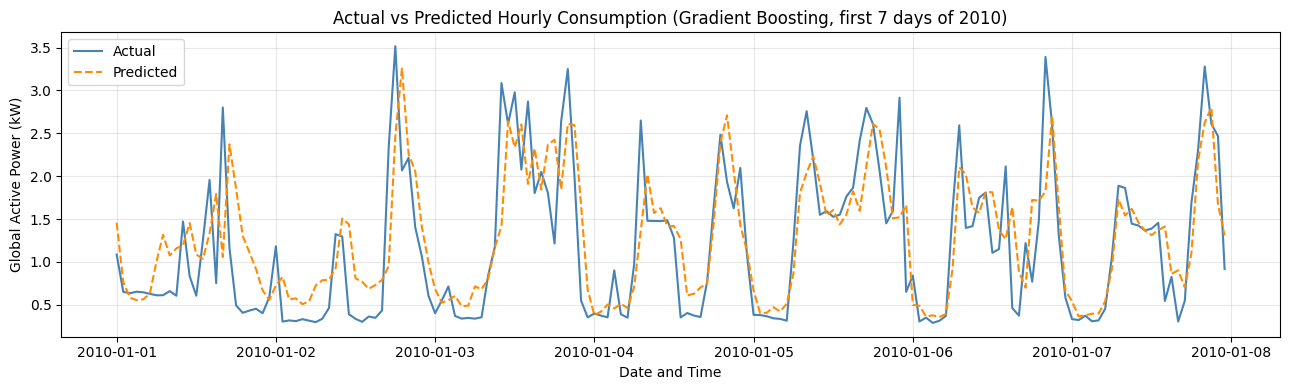

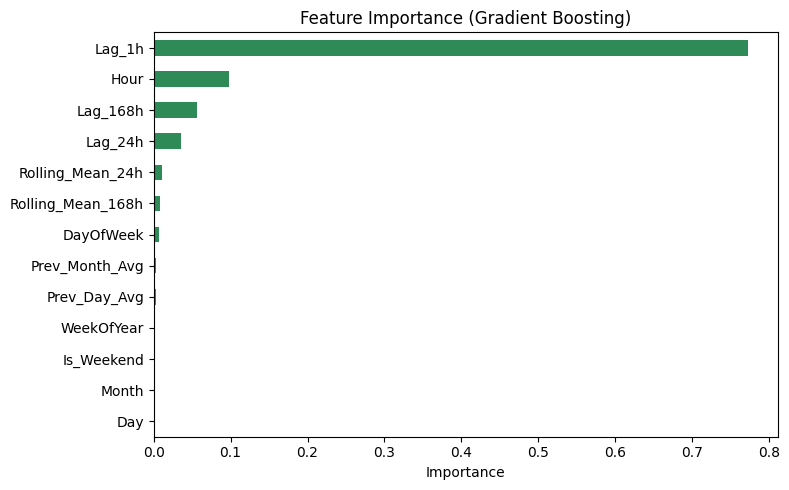

Top 5 features:
Lag_1h              0.7728
Hour                0.0984
Lag_168h            0.0561
Lag_24h             0.0350
Rolling_Mean_24h    0.0107
dtype: float64

Top 5 predicted peak hours (hour of day: avg kW):
Datetime
20    1.755
21    1.724
19    1.646
8     1.416
7     1.411
dtype: float64

Model and feature list saved.


In [13]:
# ---------- Predictions, Visualization and Saving the Model ----------
import joblib

best_name = "Gradient Boosting"
best_model = models[best_name]
y_pred = pd.Series(predictions[best_name], index=y_test.index)

# 1. Actual vs Predicted (first 7 days of the test period)
n = 24 * 7
plt.figure(figsize=(13, 4))
plt.plot(y_test.index[:n], y_test.values[:n], label="Actual", color="steelblue")
plt.plot(y_test.index[:n], y_pred.values[:n], label="Predicted", color="darkorange", linestyle="--")
plt.title("Actual vs Predicted Hourly Consumption (Gradient Boosting, first 7 days of 2010)")
plt.xlabel("Date and Time")
plt.ylabel("Global Active Power (kW)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("actual_vs_predicted.png", dpi=150)
plt.show()

# 2. Feature importance
importance = pd.Series(best_model.feature_importances_, index=features).sort_values()
plt.figure(figsize=(8, 5))
importance.plot(kind="barh", color="seagreen")
plt.title("Feature Importance (Gradient Boosting)")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=150)
plt.show()
print("Top 5 features:")
print(importance.sort_values(ascending=False).head(5).round(4))

# 3. Predicted peak-demand hours (average predicted consumption by hour)
peak = y_pred.groupby(y_pred.index.hour).mean().sort_values(ascending=False)
print("\nTop 5 predicted peak hours (hour of day: avg kW):")
print(peak.head(5).round(3))

# 4. Save the trained model and feature list
joblib.dump(best_model, "best_model_gradient_boosting.pkl")
joblib.dump(features, "feature_list.pkl")
print("\nModel and feature list saved.")

## 9. Next-Day Forecasting Model

=== Next-Day Model vs Baseline (same hour yesterday) ===
Baseline (Lag_24h)               MAE=0.5575  RMSE=0.8241  R2=-0.1300
Gradient Boosting (day-ahead)    MAE=0.4480  RMSE=0.6126  R2=0.3755

Daily average consumption MAE: 0.1787 kW


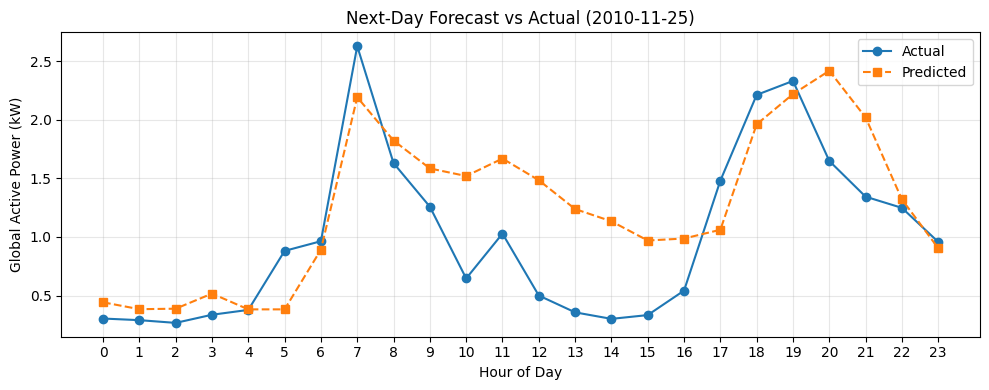

Predicted peak hour on 2010-11-25: 20:00 (2.417 kW)
Day-ahead model saved.


In [14]:
# ---------- Next-Day Forecasting Model ----------
# Uses ONLY information available before the forecast day starts (lags >= 24 hours)

target = "Global_active_power"
dd = hourly[[target]].copy()
s = dd[target]

# Time features
dd["Hour"] = dd.index.hour
dd["Day"] = dd.index.day
dd["DayOfWeek"] = dd.index.dayofweek
dd["Month"] = dd.index.month
dd["WeekOfYear"] = dd.index.isocalendar().week.astype(int).values
dd["Is_Weekend"] = (dd["DayOfWeek"] >= 5).astype(int)

# Lag features (all at least 24 hours old)
dd["Lag_24h"] = s.shift(24)
dd["Lag_48h"] = s.shift(48)
dd["Lag_168h"] = s.shift(168)
dd["Rolling_Mean_168h"] = s.shift(24).rolling(168).mean()

# Average consumption of the previous day
daily = s.resample("D").mean()
dd["Prev_Day_Avg"] = daily.reindex(dd.index.normalize() - pd.Timedelta(days=1)).values

dd = dd.dropna()
day_features = [c for c in dd.columns if c != target]

# Chronological split
tr = dd.loc[:"2009-12-31"]
te = dd.loc["2010-01-01":]

day_model = GradientBoostingRegressor(n_estimators=200, random_state=42)
day_model.fit(tr[day_features], tr[target])
day_pred = pd.Series(day_model.predict(te[day_features]), index=te.index)

# Evaluate against baseline "same hour yesterday"
base = te["Lag_24h"]
print("=== Next-Day Model vs Baseline (same hour yesterday) ===")
for name, p in [("Baseline (Lag_24h)", base), ("Gradient Boosting (day-ahead)", day_pred)]:
    mae = mean_absolute_error(te[target], p)
    rmse = np.sqrt(mean_squared_error(te[target], p))
    r2 = r2_score(te[target], p)
    print("{:32s} MAE={:.4f}  RMSE={:.4f}  R2={:.4f}".format(name, mae, rmse, r2))

# Daily average error
act_d = te[target].groupby(te.index.date).mean()
prd_d = day_pred.groupby(day_pred.index.date).mean()
print("\nDaily average consumption MAE: {:.4f} kW".format(mean_absolute_error(act_d, prd_d)))

# Forecast for the last complete day in the data
counts = te[target].groupby(te.index.date).size()
last_day = counts[counts == 24].index[-1]
d_act = te.loc[str(last_day), target]
d_prd = day_pred.loc[str(last_day)]

plt.figure(figsize=(10, 4))
plt.plot(d_act.index.hour, d_act.values, marker="o", label="Actual")
plt.plot(d_prd.index.hour, d_prd.values, marker="s", linestyle="--", label="Predicted")
plt.title("Next-Day Forecast vs Actual ({})".format(last_day))
plt.xlabel("Hour of Day")
plt.ylabel("Global Active Power (kW)")
plt.xticks(range(0, 24))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("next_day_forecast.png", dpi=150)
plt.show()

print("Predicted peak hour on {}: {}:00 ({:.3f} kW)".format(
    last_day, d_prd.idxmax().hour, d_prd.max()))

# Save the day-ahead model
joblib.dump(day_model, "day_ahead_model.pkl")
joblib.dump(day_features, "day_ahead_features.pkl")
print("Day-ahead model saved.")

## 10. Prediction Functions (next hour / next day)

In [15]:
# ---------- Prediction Functions ----------
hist_all = hourly["Global_active_power"]

def predict_next_hour(ts):
    """Predict consumption for the hour starting at timestamp ts,
    using only data before ts."""
    ts = pd.Timestamp(ts)
    h = hist_all.loc[:ts - pd.Timedelta(hours=1)]
    one = pd.Timedelta(hours=1)
    prev_month = str(ts.to_period("M") - 1)
    row = {
        "Hour": ts.hour, "Day": ts.day, "DayOfWeek": ts.dayofweek,
        "Month": ts.month, "WeekOfYear": int(ts.isocalendar().week),
        "Is_Weekend": int(ts.dayofweek >= 5),
        "Lag_1h": h.loc[ts - one],
        "Lag_24h": h.loc[ts - 24 * one],
        "Lag_168h": h.loc[ts - 168 * one],
        "Rolling_Mean_24h": h.loc[ts - 24 * one: ts - one].mean(),
        "Rolling_Mean_168h": h.loc[ts - 168 * one: ts - one].mean(),
        "Prev_Day_Avg": h.loc[str((ts - pd.Timedelta(days=1)).date())].mean(),
        "Prev_Month_Avg": h.loc[prev_month].mean(),
    }
    X = pd.DataFrame([row])[features]
    return float(best_model.predict(X)[0])

def predict_next_day(day):
    """Predict all 24 hours of a given day using only data up to the end of the previous day."""
    day = pd.Timestamp(day).normalize()
    h = hist_all.loc[:day - pd.Timedelta(hours=1)]
    one = pd.Timedelta(hours=1)
    prev_day_avg = h.loc[str((day - pd.Timedelta(days=1)).date())].mean()
    rows = []
    for hr in range(24):
        ts = day + hr * one
        rows.append({
            "Hour": ts.hour, "Day": ts.day, "DayOfWeek": ts.dayofweek,
            "Month": ts.month, "WeekOfYear": int(ts.isocalendar().week),
            "Is_Weekend": int(ts.dayofweek >= 5),
            "Lag_24h": h.loc[ts - 24 * one],
            "Lag_48h": h.loc[ts - 48 * one],
            "Lag_168h": h.loc[ts - 168 * one],
            "Rolling_Mean_168h": h.loc[ts - 191 * one: ts - 24 * one].mean(),
            "Prev_Day_Avg": prev_day_avg,
        })
    X = pd.DataFrame(rows)[day_features]
    return pd.Series(day_model.predict(X),
                     index=pd.date_range(day, periods=24, freq="h"))

# Demo 1: next-hour prediction
ts = "2010-11-25 20:00"
print("Next-hour prediction for", ts, ":", round(predict_next_hour(ts), 3), "kW")
print("Actual value:", round(hist_all.loc[ts], 3), "kW")

# Demo 2: next-day prediction
pred_day = predict_next_day("2010-11-25")
print("\nNext-day forecast for 2010-11-25:")
print(pred_day.round(3).to_string())
print("\nPredicted peak hour:", pred_day.idxmax().hour, ":00")

# ---------- Save all files and download ----------
import glob, shutil, os
from google.colab import files

os.makedirs("project_outputs", exist_ok=True)
for pattern in ["*.png", "*.pkl", "*.csv"]:
    for f in glob.glob(pattern):
        shutil.copy(f, "project_outputs")
shutil.make_archive("project_outputs", "zip", "project_outputs")
files.download("project_outputs.zip")

Next-hour prediction for 2010-11-25 20:00 : 2.485 kW
Actual value: 1.648 kW

Next-day forecast for 2010-11-25:
2010-11-25 00:00:00    0.442
2010-11-25 01:00:00    0.383
2010-11-25 02:00:00    0.387
2010-11-25 03:00:00    0.516
2010-11-25 04:00:00    0.382
2010-11-25 05:00:00    0.382
2010-11-25 06:00:00    0.891
2010-11-25 07:00:00    2.191
2010-11-25 08:00:00    1.822
2010-11-25 09:00:00    1.584
2010-11-25 10:00:00    1.519
2010-11-25 11:00:00    1.668
2010-11-25 12:00:00    1.483
2010-11-25 13:00:00    1.238
2010-11-25 14:00:00    1.133
2010-11-25 15:00:00    0.969
2010-11-25 16:00:00    0.986
2010-11-25 17:00:00    1.061
2010-11-25 18:00:00    1.960
2010-11-25 19:00:00    2.218
2010-11-25 20:00:00    2.417
2010-11-25 21:00:00    2.019
2010-11-25 22:00:00    1.320
2010-11-25 23:00:00    0.904
Freq: h

Predicted peak hour: 20 :00


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>